# 01 · Classic EDA — USGS river-gauge data
**Project:** Real-Time Flood & Flash-Flood Forecasting and Alerting using Apache Kafka

**Dataset:** USGS Instantaneous Values (IV) web service — river stage (gage height, parameter `00065`, ft) and discharge (`00060`, cfs), recorded every 15 min.
This notebook does a classic exploratory analysis: structure, data quality, distributions, time-series behaviour, seasonality, relationships, dependence and outliers.

**How to run:** Colab or Kaggle (Kaggle: turn *Internet* on in settings). Edit the config cell, then *Run all*. Downloads are cached in `data/`.

In [24]:
!pip install -q statsmodels seaborn matplotlib pandas


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Setup and configuration

In [25]:
import json, os, time, gzip, io, math
from datetime import datetime, timedelta, timezone
import numpy as np
import pandas as pd
import requests

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
UA = {"User-Agent": "dews-flood-eda-notebook"}

def get_json(url, params=None, retries=3):
    """GET with retries; raises on final failure."""
    last = None
    for i in range(retries):
        try:
            r = requests.get(url, params=params, headers=UA, timeout=60)
            r.raise_for_status()
            return r.json()
        except Exception as e:
            last = e
            time.sleep(2 * (i + 1))
    raise RuntimeError(f"GET failed: {url} {params}: {last}")

def parse_iv(doc):
    """USGS Instantaneous Values JSON -> tidy DataFrame (one row per reading)."""
    rows, sites = [], {}
    for ts in doc["value"]["timeSeries"]:
        src, var = ts["sourceInfo"], ts["variable"]
        site = src["siteCode"][0]["value"]
        geo = src.get("geoLocation", {}).get("geogLocation", {})
        sites[site] = {"site_no": site, "site_name": src.get("siteName"),
                       "lat": geo.get("latitude"), "lon": geo.get("longitude")}
        param = var["variableCode"][0]["value"]
        nodata = var.get("noDataValue")
        for i, block in enumerate(ts.get("values", [])):
            meth = (block.get("method") or [{}])[0]
            series = str(meth.get("methodID", i))
            mdesc = meth.get("methodDescription", "")
            for pt in block.get("value", []):
                try:
                    v = float(pt["value"])
                except (TypeError, ValueError):
                    continue
                rows.append((site, param, series, mdesc, pt["dateTime"], v,
                             ",".join(pt.get("qualifiers") or []), v == nodata))
    df = pd.DataFrame(rows, columns=["site_no", "parameter", "series", "method", "dateTime",
                                     "value", "qualifiers", "is_nodata"])
    if len(df):
        df["datetime_utc"] = pd.to_datetime(df["dateTime"], utc=True, format="ISO8601")
        df = df.drop(columns="dateTime")
    return df, pd.DataFrame(sites.values())

def fetch_iv(sites, params, start, end, chunk_days=120, cache=True):
    """Fetch USGS IV data in chunks (the service limits request sizes)."""
    key = f"iv_{'-'.join(sites)}_{'-'.join(params)}_{start}_{end}.csv.gz"
    path = os.path.join(DATA_DIR, key)
    meta_path = path.replace(".csv.gz", "_sites.csv")
    if cache and os.path.exists(path) and os.path.exists(meta_path):
        df = pd.read_csv(path, dtype={"site_no": str, "parameter": str, "series": str})
        df["datetime_utc"] = pd.to_datetime(df["datetime_utc"], utc=True, format="ISO8601")
        return df, pd.read_csv(meta_path, dtype={"site_no": str})
    frames, metas = [], []
    t0, t1 = pd.Timestamp(start), pd.Timestamp(end)
    cur = t0
    while cur < t1:
        nxt = min(cur + pd.Timedelta(days=chunk_days), t1)
        doc = get_json("https://waterservices.usgs.gov/nwis/iv/",
                       {"format": "json", "sites": ",".join(sites), "parameterCd": ",".join(params),
                        "startDT": cur.strftime("%Y-%m-%d"), "endDT": nxt.strftime("%Y-%m-%d"),
                        "siteStatus": "all"})
        d, m = parse_iv(doc)
        frames.append(d); metas.append(m)
        print(f"  {cur.date()} .. {nxt.date()}: {len(d):,} readings")
        cur = nxt + pd.Timedelta(days=1)
    df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    meta = pd.concat(metas).drop_duplicates("site_no") if metas else pd.DataFrame()
    df = df.drop_duplicates(["site_no", "parameter", "series", "datetime_utc"])
    if cache:
        df.to_csv(path, index=False); meta.to_csv(meta_path, index=False)
    return df, meta

def primary_series(df, site, param):
    """The series with the most readings is treated as the primary sensor."""
    d = df[(df.site_no == site) & (df.parameter == param) & (~df.is_nodata)]
    if d.empty:
        return pd.Series(dtype=float)
    s = d.series.value_counts().idxmax()
    out = d[d.series == s].set_index("datetime_utc")["value"].sort_index()
    return out[~out.index.duplicated()]

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

# ---- CONFIG: put your candidate gauges here (USGS site numbers) ----
SITES  = ["08158700", "08172400"]          # DRWT2 Onion Creek (5-min), LCPT2 Plum Creek (15-min): the two gauges that pass the gate
PARAMS = ["00065", "00060"]                # gage height (ft), discharge (cfs)
END    = pd.Timestamp.now(tz="UTC").normalize().tz_localize(None)
START  = END - pd.Timedelta(days=730)      # last 2 years at 15-min resolution
PNAME  = {"00065": "stage_ft", "00060": "discharge_cfs"}

## 2. Load data

In [27]:
df, sites_meta = fetch_iv(SITES, PARAMS, START.date().isoformat(), END.date().isoformat())
df["variable"] = df["parameter"].map(PNAME)
print(f"{len(df):,} rows")
sites_meta

  2024-10-03 .. 2025-01-31: 92,930 readings
  2025-02-01 .. 2025-06-01: 89,948 readings
  2025-06-02 .. 2025-09-30: 91,954 readings
  2025-10-01 .. 2026-01-29: 91,942 readings
  2026-01-30 .. 2026-05-30: 92,886 readings
  2026-05-31 .. 2026-09-28: 91,352 readings
  2026-09-29 .. 2026-10-03: 3,190 readings
554,202 rows


,site_no,site_name,lat,lon
0,08158700,"Onion Ck nr Driftwood, TX",30.082989,-98.007786
1,08172400,"Plum Ck at Lockhart, TX",29.922998,-97.679191


## 3. Structure of the data

In [28]:
print(df.dtypes, "\n")
display(df.head())
summary = (df.groupby(["site_no", "variable", "series", "method"])
             .agg(readings=("value", "size"), first=("datetime_utc", "min"), last=("datetime_utc", "max"))
             .reset_index())
summary

site_no                         str
parameter                       str
series                          str
method                          str
value                       float64
qualifiers                      str
is_nodata                      bool
datetime_utc    datetime64[us, UTC]
variable                        str
dtype: object 



,site_no,parameter,series,method,value,qualifiers,is_nodata,datetime_utc,variable
0,08158700,00060,141338,[15-Minute Updates],0.09,A,False,2024-10-03 05:00:00+00:00,discharge_cfs
1,08158700,00060,141338,[15-Minute Updates],0.09,A,False,2024-10-03 05:05:00+00:00,discharge_cfs
2,08158700,00060,141338,[15-Minute Updates],0.09,A,False,2024-10-03 05:10:00+00:00,discharge_cfs
3,08158700,00060,141338,[15-Minute Updates],0.09,A,False,2024-10-03 05:15:00+00:00,discharge_cfs
4,08158700,00060,141338,[15-Minute Updates],0.09,A,False,2024-10-03 05:20:00+00:00,discharge_cfs


,site_no,variable,series,method,readings,first,last
0,08158700,discharge_cfs,141338,[15-Minute Updates],205337,2024-10-03 05:00:00+00:00,2026-10-03 08:45:00+00:00
1,08158700,stage_ft,141337,[15-Minute Updates],208723,2024-10-03 05:00:00+00:00,2026-10-03 08:45:00+00:00
2,08172400,discharge_cfs,141616,,70071,2024-10-03 05:00:00+00:00,2026-10-03 08:00:00+00:00
3,08172400,stage_ft,141617,,70071,2024-10-03 05:00:00+00:00,2026-10-03 08:00:00+00:00


**Read this table:** one gauge can report **more than one sensor series** for the same variable (e.g. a primary and a backup sensor). They are kept apart everywhere below; the series with most readings is treated as primary.

## 4. Data quality
### 4.1 Missing values, no-data codes and duplicates

In [29]:
q = (df.groupby(["site_no", "variable"])
       .agg(rows=("value", "size"), nodata_codes=("is_nodata", "sum"),
            nulls=("value", lambda s: s.isna().sum()))
       .reset_index())
dups = df.duplicated(["site_no", "parameter", "series", "datetime_utc"]).sum()
print("duplicate (site, parameter, series, time) rows:", dups)
q

duplicate (site, parameter, series, time) rows: 0


,site_no,variable,rows,nodata_codes,nulls
0,08158700,discharge_cfs,205337,0,0
1,08158700,stage_ft,208723,0,0
2,08172400,discharge_cfs,70071,0,0
3,08172400,stage_ft,70071,0,0


### 4.2 Data-quality qualifiers (P = provisional, A = approved, Eqp = equipment problem, …)

In [30]:
qual = (df.assign(q=df["qualifiers"].fillna("").str.split(","))
          .explode("q").groupby(["site_no", "variable", "q"]).size().unstack(fill_value=0))
display(qual)
recent = df[df.datetime_utc > df.datetime_utc.max() - pd.Timedelta(days=60)]
print("share provisional in the last 60 days:",
      round(recent.qualifiers.str.contains("P").mean() * 100, 1), "%")
print("share provisional overall:", round(df.qualifiers.str.contains("P").mean() * 100, 1), "%")

q                            A      P    e
site_no  variable                         
08158700 discharge_cfs  186982  18355  403
         stage_ft       190368  18355    0
08172400 discharge_cfs   51681  18390    0
         stage_ft        51681  18390    0

share provisional in the last 60 days: 100.0 %
share provisional overall: 13.3 %


### 4.3 Sampling interval and gaps

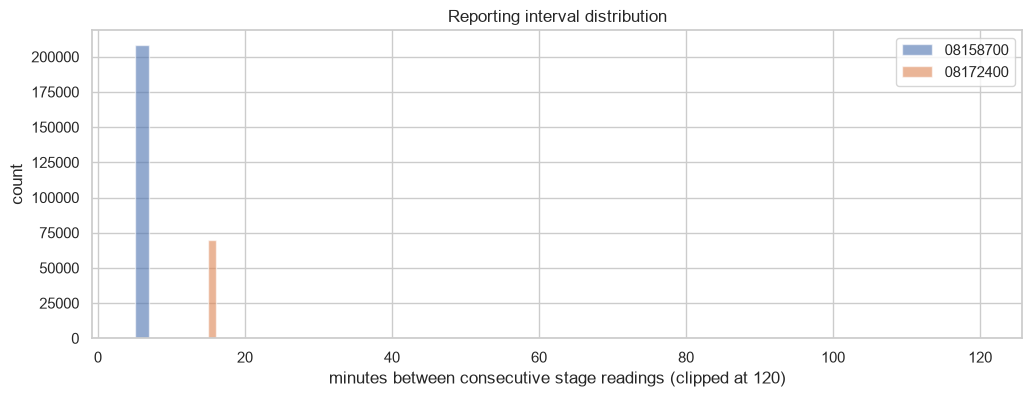

,site_no,median_interval_min,p95_interval_min,max_gap_h,gaps_over_1h,gaps_over_1d
0,08158700,5.0,5.0,67.833333,6,1
1,08172400,15.0,15.0,1.250000,5,0


In [31]:
rows = []
for site in SITES:
    s = primary_series(df, site, "00065")
    if s.empty: continue
    gaps = s.index.to_series().diff().dropna().dt.total_seconds() / 60
    rows.append({"site_no": site, "median_interval_min": gaps.median(),
                 "p95_interval_min": gaps.quantile(.95), "max_gap_h": gaps.max() / 60,
                 "gaps_over_1h": int((gaps > 60).sum()), "gaps_over_1d": int((gaps > 1440).sum())})
    plt.hist(gaps.clip(upper=120), bins=60, alpha=.6, label=site)
plt.xlabel("minutes between consecutive stage readings (clipped at 120)"); plt.ylabel("count")
plt.title("Reporting interval distribution"); plt.legend(); plt.show()
pd.DataFrame(rows)

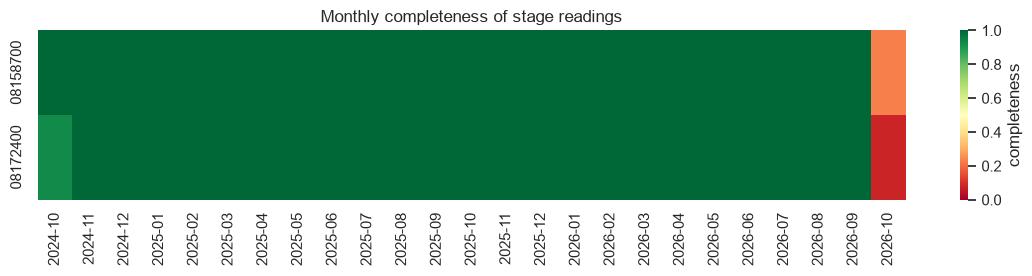

In [32]:
# Completeness: share of expected 15-min readings present, per month
comp = {}
for site in SITES:
    s = primary_series(df, site, "00065")
    if s.empty: continue
    comp[site] = (s.resample("MS").size() / (s.resample("MS").size().index.days_in_month * 96)).clip(upper=1)
comp = pd.DataFrame(comp).T
comp.columns = [c.strftime("%Y-%m") for c in comp.columns]
plt.figure(figsize=(14, 1.2 + .5 * len(comp)))
sns.heatmap(comp, vmin=0, vmax=1, cmap="RdYlGn", cbar_kws={"label": "completeness"})
plt.title("Monthly completeness of stage readings"); plt.show()

### 4.4 Do the sensor series agree?

In [33]:
for site in SITES:
    d = df[(df.site_no == site) & (df.parameter == "00065") & (~df.is_nodata)]
    if d.series.nunique() < 2:
        print(site, ": single stage series"); continue
    w = d.pivot_table(index="datetime_utc", columns="series", values="value")
    display(w.describe().T.assign(site=site))
    w.resample("D").mean().plot(title=f"{site}: daily mean stage per sensor series"); plt.show()

08158700 : single stage series
08172400 : single stage series


## 5. Univariate distributions

In [34]:
desc = df[~df.is_nodata].groupby(["site_no", "variable"])["value"].describe(
    percentiles=[.01, .25, .5, .75, .99])
desc

count       mean        std   min    1%   25%  \
site_no  variable                                                          
08158700 discharge_cfs  205337.0   1.168762  10.263929  0.00  0.00  0.00   
         stage_ft       208723.0   1.710091   0.675311  0.41  0.46  0.98   
08172400 discharge_cfs   70071.0  17.697914  49.407813  2.48  3.03  5.36   
         stage_ft        70071.0   2.247958   0.691576  1.70  1.78  1.96   

                         50%    75%      99%      max  
site_no  variable                                      
08158700 discharge_cfs  0.00   0.58   14.364   754.00  
         stage_ft       2.02   2.30    2.630     5.49  
08172400 discharge_cfs  7.11  13.00  178.000  1520.00  
         stage_ft       2.06   2.27    5.100    13.73

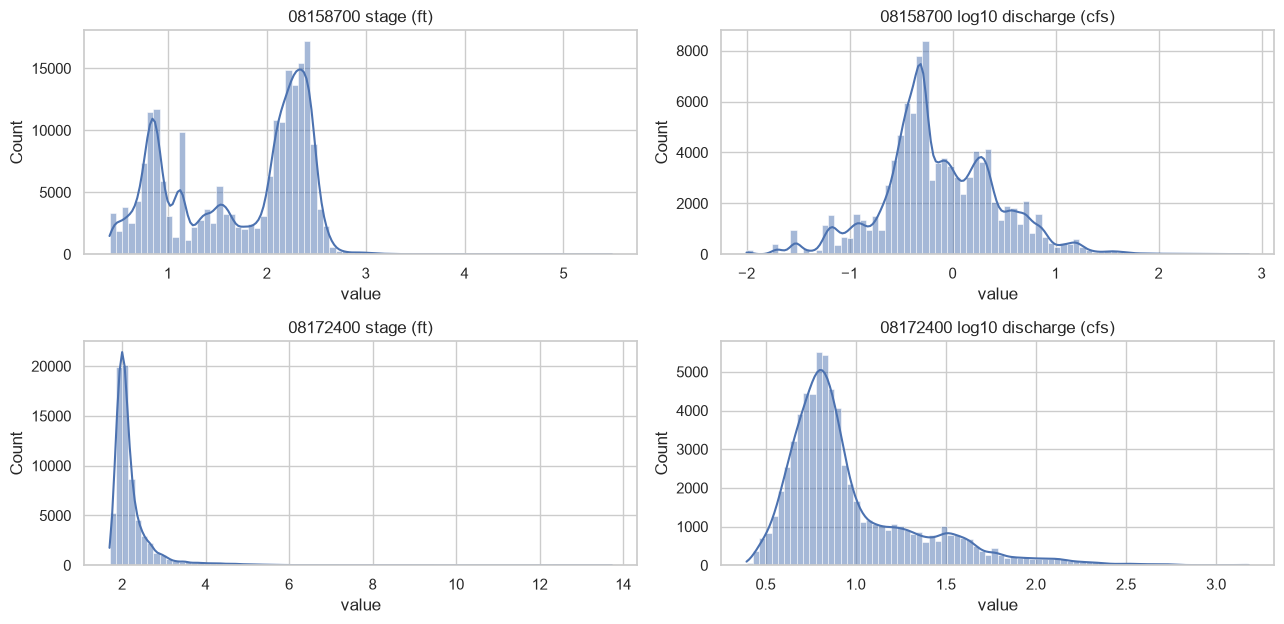

Skewness of stage: {'08158700': np.float64(-0.34), '08172400': np.float64(6.39)}


In [35]:
fig, axes = plt.subplots(len(SITES), 2, figsize=(13, 3.2 * len(SITES)), squeeze=False)
for i, site in enumerate(SITES):
    st = primary_series(df, site, "00065"); q_ = primary_series(df, site, "00060")
    if not st.empty:
        sns.histplot(st, bins=80, ax=axes[i, 0], kde=True); axes[i, 0].set_title(f"{site} stage (ft)")
    if not q_.empty:
        sns.histplot(np.log10(q_[q_ > 0]), bins=80, ax=axes[i, 1], kde=True)
        axes[i, 1].set_title(f"{site} log10 discharge (cfs)")
plt.tight_layout(); plt.show()
print("Skewness of stage:", {s: round(primary_series(df, s, '00065').skew(), 2) for s in SITES})

Flow data are usually strongly right-skewed: long quiet periods and rare, large peaks — exactly the floods we care about. Log scales and quantiles are therefore more informative than means.

## 6. Time-series behaviour

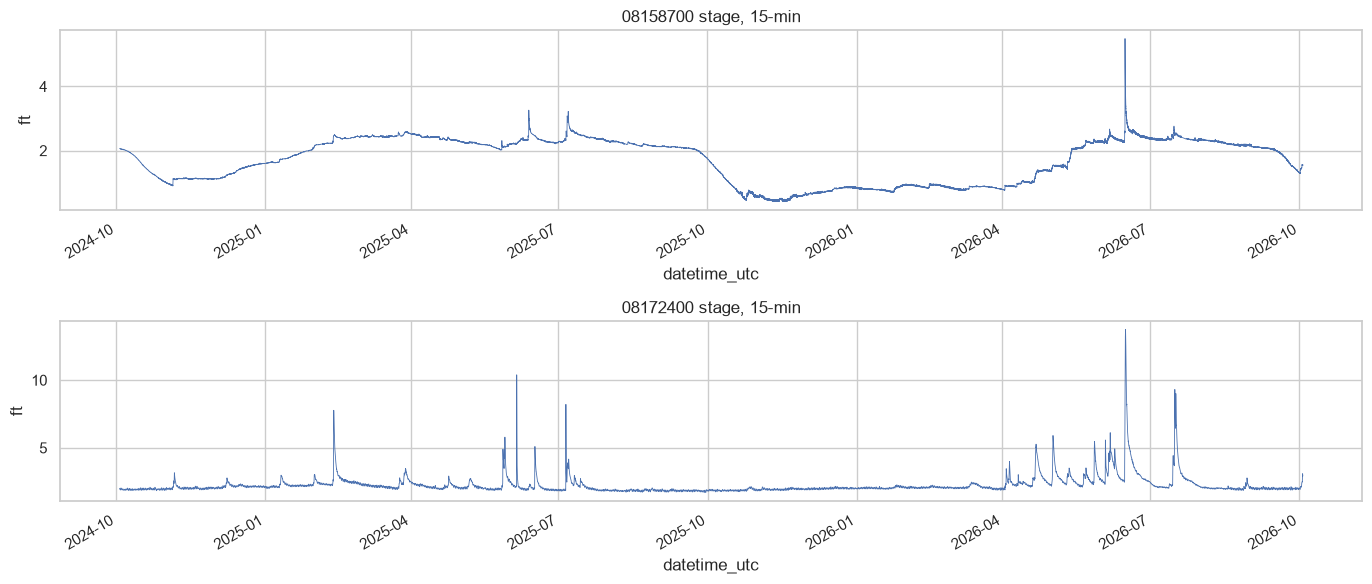

In [36]:
fig, axes = plt.subplots(len(SITES), 1, figsize=(14, 3 * len(SITES)), squeeze=False)
for i, site in enumerate(SITES):
    s = primary_series(df, site, "00065")
    if s.empty: continue
    s.plot(ax=axes[i, 0], lw=.6); axes[i, 0].set_title(f"{site} stage, 15-min"); axes[i, 0].set_ylabel("ft")
plt.tight_layout(); plt.show()

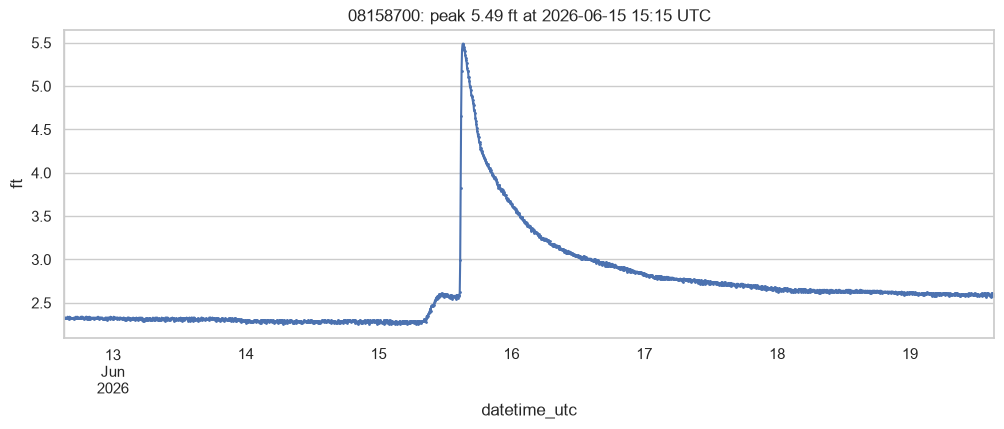

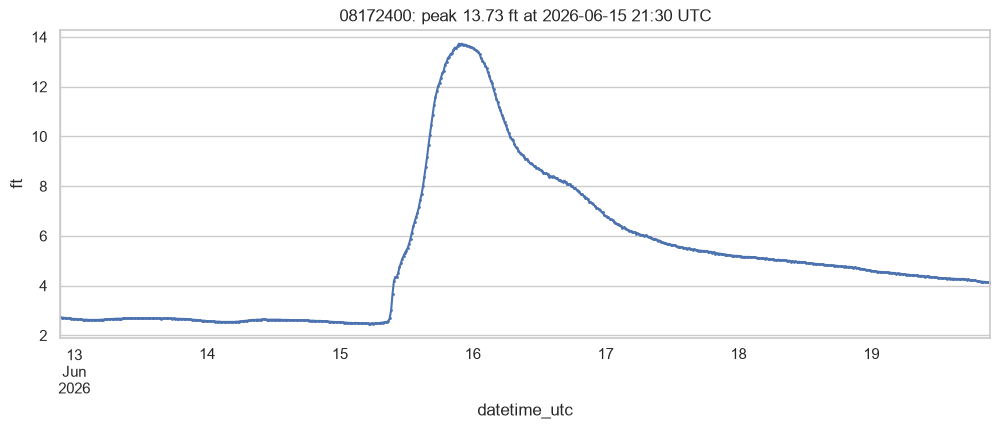

In [37]:
# Zoom on the week around each gauge's highest stage
for site in SITES:
    s = primary_series(df, site, "00065")
    if s.empty: continue
    t = s.idxmax()
    s[t - pd.Timedelta(days=3): t + pd.Timedelta(days=4)].plot(marker=".", ms=2,
        title=f"{site}: peak {s.max():.2f} ft at {t:%Y-%m-%d %H:%M} UTC"); plt.ylabel("ft"); plt.show()

## 7. Seasonality and daily cycle

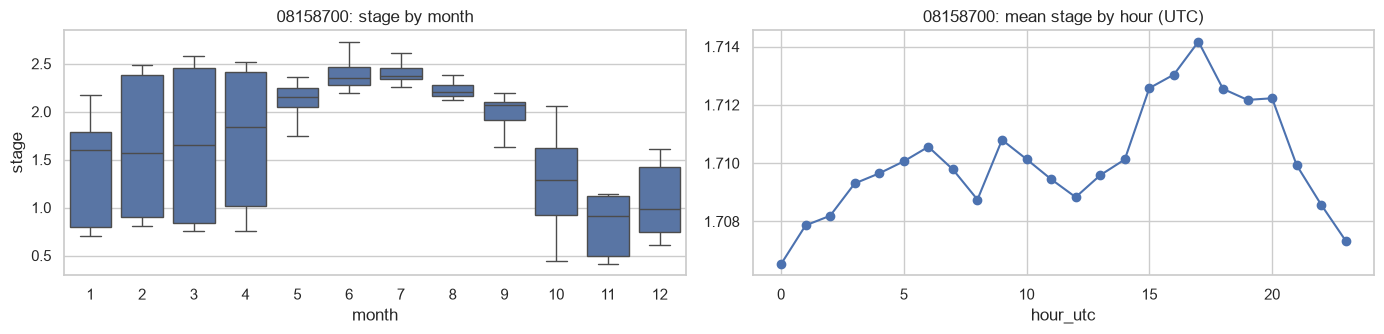

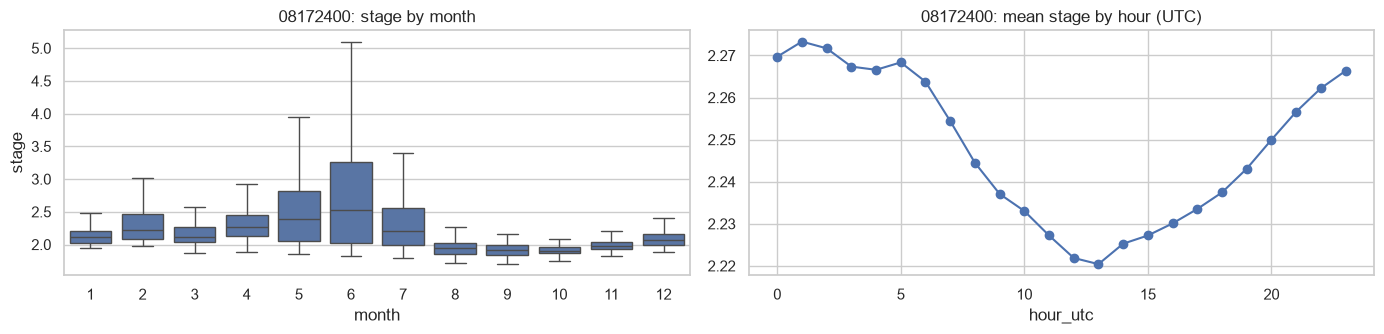

In [38]:
for site in SITES:
    s = primary_series(df, site, "00065")
    if s.empty: continue
    d = s.to_frame("stage"); d["month"] = d.index.month; d["hour_utc"] = d.index.hour
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
    sns.boxplot(data=d, x="month", y="stage", ax=ax[0], showfliers=False); ax[0].set_title(f"{site}: stage by month")
    d.groupby("hour_utc")["stage"].mean().plot(ax=ax[1], marker="o"); ax[1].set_title(f"{site}: mean stage by hour (UTC)")
    plt.tight_layout(); plt.show()

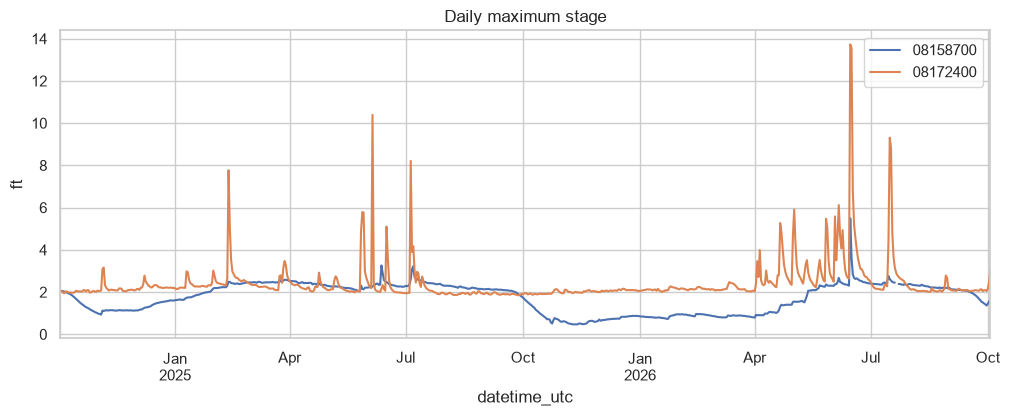

,08158700,08172400
count,729.000000,731.000000
mean,1.735432,2.407086
std,0.693301,1.017909
min,0.470000,1.850000
25%,1.000000,2.040000
50%,2.030000,2.130000
75%,2.320000,2.360000
max,5.490000,13.730000


In [39]:
daily = pd.DataFrame({s: primary_series(df, s, "00065").resample("D").max() for s in SITES})
daily.plot(title="Daily maximum stage"); plt.ylabel("ft"); plt.show()
daily.describe()

## 8. Relationships
### 8.1 Stage–discharge (rating curve)

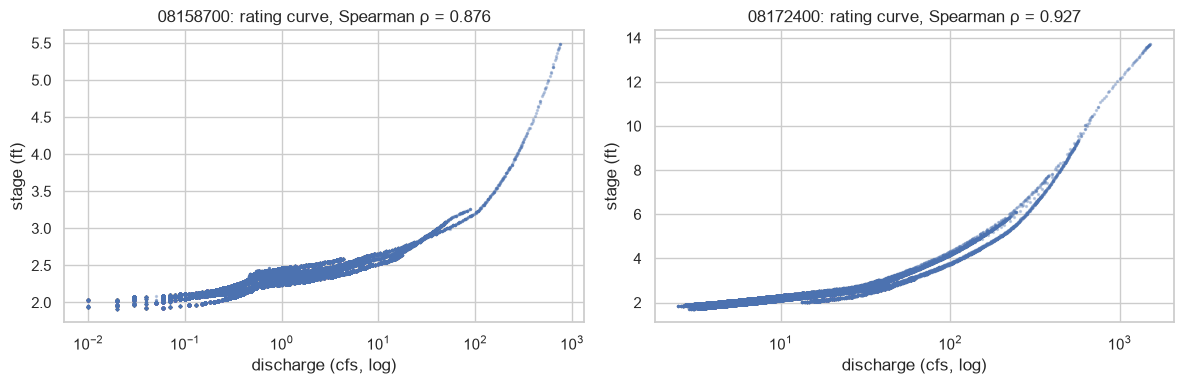

In [40]:
fig, axes = plt.subplots(1, len(SITES), figsize=(6 * len(SITES), 4), squeeze=False)
for i, site in enumerate(SITES):
    st, q_ = primary_series(df, site, "00065"), primary_series(df, site, "00060")
    j = pd.concat([st.rename("stage"), q_.rename("q")], axis=1, join="inner").dropna()
    j = j[j.q > 0]
    if j.empty: continue
    axes[0, i].scatter(j.q, j.stage, s=2, alpha=.3); axes[0, i].set_xscale("log")
    axes[0, i].set_xlabel("discharge (cfs, log)"); axes[0, i].set_ylabel("stage (ft)")
    axes[0, i].set_title(f"{site}: rating curve, Spearman ρ = {j.stage.corr(j.q, method='spearman'):.3f}")
plt.tight_layout(); plt.show()

### 8.2 Correlation between gauges (hourly stage)

,08158700,08172400
08158700,1.00000,0.32664
08172400,0.32664,1.00000


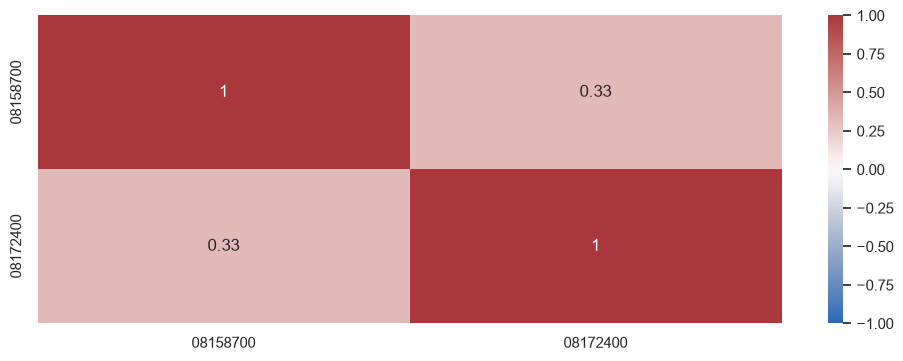

In [41]:
hourly = pd.DataFrame({s: primary_series(df, s, "00065").resample("h").mean() for s in SITES})
display(hourly.corr(method="spearman"))
if len(SITES) > 1:
    sns.heatmap(hourly.corr(method="spearman"), annot=True, vmin=-1, vmax=1, cmap="vlag"); plt.show()

## 9. Temporal dependence (what a forecaster can exploit)

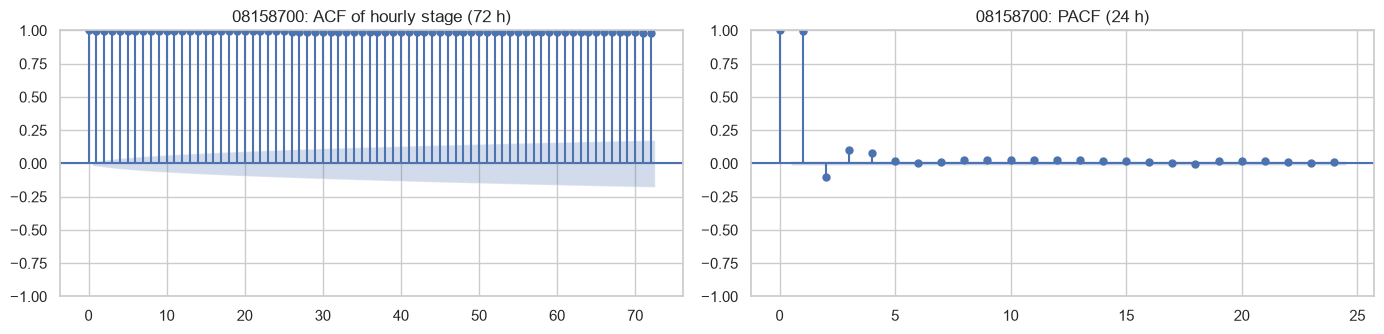

C:\Users\MY PC\AppData\Local\Temp\ipykernel_33144\3317633050.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p = adfuller(h.values[-24 * 365:], autolag="AIC")[:2]


08158700: ADF statistic -1.19, p = 0.6799 -> not shown stationary


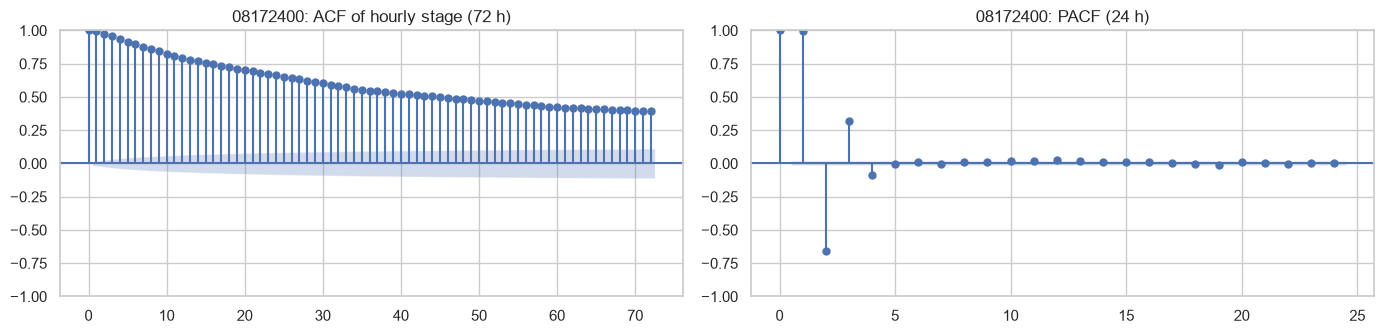

08172400: ADF statistic -6.79, p = 0.0000 -> stationary (reject unit root)


C:\Users\MY PC\AppData\Local\Temp\ipykernel_33144\3317633050.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p = adfuller(h.values[-24 * 365:], autolag="AIC")[:2]


In [42]:
for site in SITES:
    h = primary_series(df, site, "00065").resample("h").mean().interpolate(limit=6).dropna()
    if len(h) < 200: continue
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
    plot_acf(h, lags=72, ax=ax[0], title=f"{site}: ACF of hourly stage (72 h)")
    plot_pacf(h, lags=24, ax=ax[1], method="ywm", title=f"{site}: PACF (24 h)")
    plt.tight_layout(); plt.show()
    stat, p = adfuller(h.values[-24 * 365:], autolag="AIC")[:2]
    print(f"{site}: ADF statistic {stat:.2f}, p = {p:.4f} ->",
          "stationary (reject unit root)" if p < .05 else "not shown stationary")

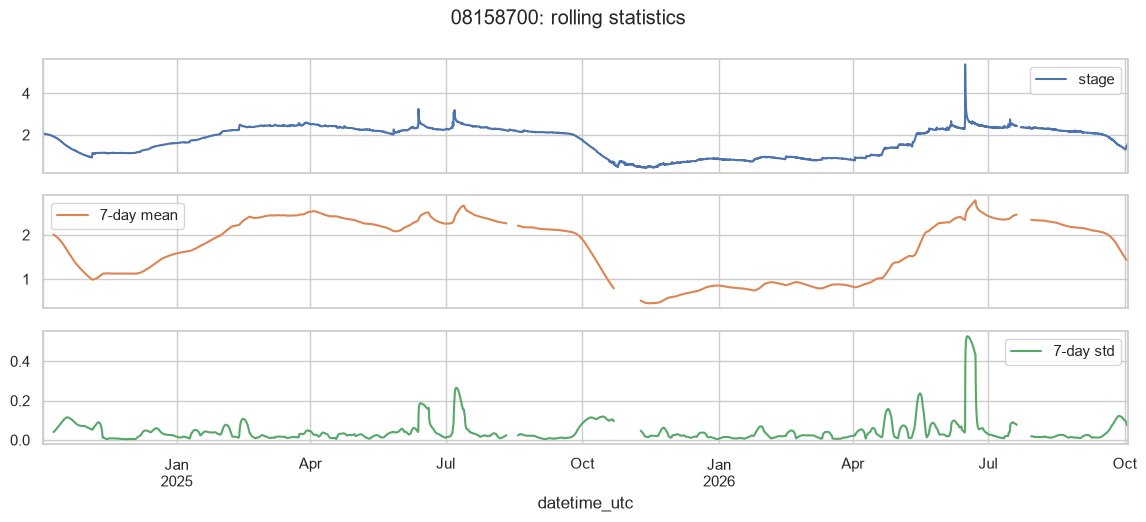

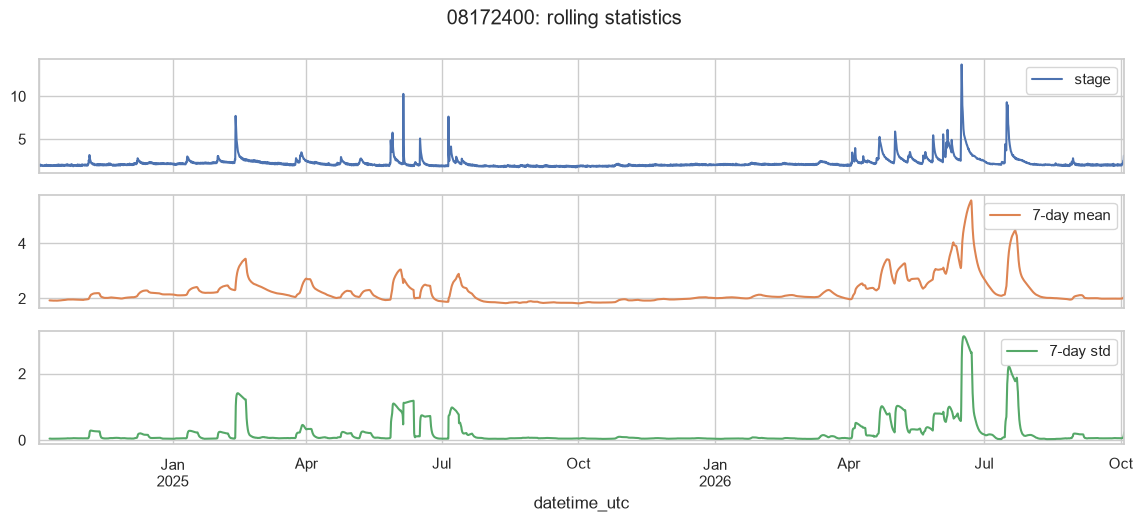

In [43]:
for site in SITES:
    h = primary_series(df, site, "00065").resample("h").mean()
    roll = pd.DataFrame({"stage": h, "7-day mean": h.rolling(24 * 7).mean(), "7-day std": h.rolling(24 * 7).std()})
    roll.plot(subplots=True, figsize=(14, 5), title=f"{site}: rolling statistics"); plt.show()

## 10. Outliers and sudden changes

In [44]:
out = []
for site in SITES:
    s = primary_series(df, site, "00065")
    if s.empty: continue
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    z = (s - s.rolling(96, min_periods=24).mean()) / s.rolling(96, min_periods=24).std()
    dt_h = s.index.to_series().diff().dt.total_seconds() / 3600
    rate = (s.diff() / dt_h).replace([np.inf, -np.inf], np.nan)
    out.append({"site_no": site, "iqr_outliers": int(((s < q1 - 3 * iqr) | (s > q3 + 3 * iqr)).sum()),
                "rolling_|z|>4": int((z.abs() > 4).sum()),
                "max_rise_ft_per_h": round(rate.max(), 2), "max_fall_ft_per_h": round(rate.min(), 2)})
    print(f"{site}: 5 largest rises (ft/h)"); display(rate.nlargest(5).to_frame("ft_per_h"))
pd.DataFrame(out)

08158700: 5 largest rises (ft/h)


,ft_per_h
datetime_utc,
2026-06-15 14:50:00+00:00,10.08
2026-06-15 14:55:00+00:00,9.84
2026-06-15 15:00:00+00:00,6.36
2026-06-15 14:45:00+00:00,4.44
2026-06-15 15:05:00+00:00,2.88


08172400: 5 largest rises (ft/h)


,ft_per_h
datetime_utc,
2025-07-05 14:00:00+00:00,7.32
2025-06-05 04:30:00+00:00,7.24
2025-07-05 13:45:00+00:00,6.56
2025-06-05 04:45:00+00:00,5.52
2025-07-05 14:15:00+00:00,4.20


,site_no,iqr_outliers,rolling_|z|>4,max_rise_ft_per_h,max_fall_ft_per_h
0,08158700,0,1624,10.08,-0.84
1,08172400,3477,169,7.32,-2.00


**Interpretation:** a large rise in stage is not automatically an error — floods *are* the outliers we need to detect. A sensor fault usually shows up as an isolated spike that the backup series does not show, a flat line, or a `Eqp`/`Ice` qualifier. These checks feed the pipeline's false-alarm guards.

## 11. Summary

In [45]:
rows = []
for site in SITES:
    s = primary_series(df, site, "00065")
    if s.empty: continue
    gaps = s.index.to_series().diff().dt.total_seconds() / 60
    rows.append({"site_no": site, "readings": len(s), "from": s.index.min().date(), "to": s.index.max().date(),
                 "median_interval_min": gaps.median(), "max_stage_ft": s.max(), "median_stage_ft": s.median(),
                 "stage_series": df[(df.site_no == site) & (df.parameter == "00065")].series.nunique()})
summary = pd.DataFrame(rows); summary.to_csv(os.path.join(DATA_DIR, "eda01_summary.csv"), index=False)
summary

,site_no,readings,from,to,median_interval_min,max_stage_ft,median_stage_ft,stage_series
0,08158700,208723,2024-10-03,2026-10-03,5.0,5.49,2.02,1
1,08172400,70071,2024-10-03,2026-10-03,15.0,13.73,2.06,1
